# Wrong-wavelength ablation — OxHyp / EuroCrops / BNETD / BDForêt

- Metadata-sensitivity test: full band set kept, but the wavelength metadata given to each encoder is corrupted
- Wrong-Permuted: true per-band wavelengths reassigned to different bands (3 seeds)
- Wrong-Constant: every band told the sensor's median true wavelength
- Wrong-Jitter: each band's true wavelength nudged by ±20–50 nm
- Shuffled: pixel data and wavelength reordered together, so the pairing stays correct — only band order changes
- Reinit-Hypernetwork: wavelength metadata left correct, but the encoder's learned wavelength→weight mapping is reinitialized
- Compares each condition's mIoU against the full-band, correct-wavelength baseline

In [1]:
from __future__ import annotations

import csv
import random
import re
import statistics
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

## Configuration

Mirrors the exact naming scheme used by `run_wrong_wavelength_ablation.sh` / `run_wrong_wavelength_universat.sh`.
If either script's naming changes, update it here too.

In [2]:
DISK_ROOT = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments/hsi-bench")
REPO_ROOT = Path.cwd().parent  # notebooks/ -> repo root

SENSOR_YAML_PATHS = {
    "emit": REPO_ROOT / "configs/sensor/emit.yaml",
    "enmap": REPO_ROOT / "configs/sensor/enmap.yaml",
}

TASKS = ["oxhyperminerals_emit_l2a", "eurocrops", "bnetd", "bdforet"]
# UniverSat-B is deliberately scoped to only the original 3 tasks -- see
# intro markdown for why BDForêt was dropped for it specifically.
UNIVERSAT_TASKS = ["oxhyperminerals_emit_l2a", "eurocrops", "bnetd"]
TASK_LABELS = {
    "oxhyperminerals_emit_l2a": "OxHyp",
    "eurocrops": "EuroCrops",
    "bnetd": "BNETD",
    "bdforet": "BDForêt",
}
TASK_SENSOR = {
    "oxhyperminerals_emit_l2a": "emit",
    "eurocrops": "enmap",
    "bnetd": "enmap",
    "bdforet": "enmap",
}

BACKBONES = ["dofa_b", "dofav2_b", "copernicus_fm_b", "panopticon_b", "carl"]
# The only 3 encoders with an actual weight-generating hypernetwork
# (Dynamic_MLP_OFA / _DynamicMLPSpectral) -- Reinit-Hypernetwork only applies
# to these; Panopticon-B/CARL use different conditioning mechanisms with no
# equivalent submodule to reinit, see intro markdown.
REINIT_HYPERNETWORK_BACKBONES = ["dofa_b", "dofav2_b", "copernicus_fm_b"]
BACKBONE_LABELS = {
    "dofa_b": "DOFA",
    "dofav2_b": "DOFA+",
    "copernicus_fm_b": "Copernicus-FM",
    "panopticon_b": "Panopticon",
    "carl": "CARL",
    "vit_b": "ViT (random init)",   # Full-band point only, see intro.
    "universat_b": "UniverSat",     # Full-band point + wrong-wavelength (partial), see intro.
}
WEIGHT_INIT = {
    "dofa_b": "dofa_pretrained",
    "dofav2_b": "dofav2_pretrained",
    "copernicus_fm_b": "copernicus_fm_pretrained",
    "panopticon_b": "panopticon_pretrained",
    "carl": "carl_pretrained",
    "vit_b": "random_init",
}

SEEDS = [0, 1, 2]
# wrong_jitter/shuffled/reinit_hypernetwork only ever ran 1 seed each
# (seed 0) -- see print_wrong_wavelength_overrides.py's header /
# run_reinit_hypernetwork_ablation.sh.
# Bar order = increasing "how much is actually broken": Full (nothing wrong)
# -> Shuffled (data+labels reordered together, nothing wrong either) ->
# Wrong-Jitter (small noise) -> Wrong-Permuted (real values, wrong band) ->
# Wrong-Constant (all differentiation destroyed) -> Reinit-Hypernetwork
# (a different axis entirely -- metadata correct, but the encoder's own
# learned weight-generation mapping is destroyed instead), placed last since
# it isn't a wavelength-metadata corruption at all.
CONDITIONS = ["full", "wrong_jitter", "wrong_permuted", "wrong_constant"]  # shuffled, reinit_hypernetwork dropped per request
CONDITION_LABELS = {
    "full": "Full",
    "wrong_permuted": "Wrong-Permuted",
    "wrong_constant": "Wrong-Constant",
    "wrong_jitter": "Wrong-Jitter",
    "shuffled": "Shuffled",
    "reinit_hypernetwork": "Reinit-Hypernetwork",
}
# Severity ramp (project convention): baseline (Full) stays the
# default-cycle blue; the 3 graduated wrong-wavelength conditions sample
# plt.cm.YlOrRd between 0.35 and 0.90 (avoids near-white/near-black),
# ordered mildest -> most severe: Wrong-Jitter (small noise) -> Wrong-
# Permuted (real values, wrong band) -> Wrong-Constant (all differentiation
# destroyed). shuffled/reinit_hypernetwork keep their old colors (unused --
# dropped from CONDITIONS -- but still defined for any stray reference).
_severity_order = ["wrong_jitter", "wrong_permuted", "wrong_constant"]
_ramp = [plt.cm.YlOrRd(0.35 + 0.55 * (i / (len(_severity_order) - 1))) for i in range(len(_severity_order))]
CONDITION_COLORS = {
    "full": "#1f77b4",
    **dict(zip(_severity_order, _ramp)),
    "shuffled": "#e87ba4",
    "reinit_hypernetwork": "#008300",
}
# ViT-B (random init) only ever contributes a "Full" bar, but it isn't the
# same thing as the other backbones' Full bar (no wavelength conditioning at
# all, vs. correct wavelength conditioning) -- drawn grey with its own
# legend entry instead of sharing "Full"'s blue.
VIT_RANDOM_COLOR = "#999999"
# One additional color per seed, used only by the "where did the bands land"
# scatter plot below (a different encoding than CONDITION_COLORS -- there,
# color means "which condition"; here it means "which of the 3 permutation
# draws").
SEED_COLORS = {0: "#eb6834", 1: "#eda100", 2: "#e87ba4"}

DECODER = "mlp_fusion_head"
PROTOCOL = "linear"

VIT_B_BACKBONE = "vit_b"
UNIVERSAT_BACKBONE = "universat_b"
UNIVERSAT_DECODER = "universat_conv_head"
UNIVERSAT_WEIGHT_INIT = "universat_pretrained"

# All backbones shown in the main charts -- the 5 wavelength-conditioned
# encoders (DOFA, DOFA+, Copernicus, Panopticon, CARL), then ViT-B (random
# init) last as the pure no-wavelength-conditioning-at-all reference.
# UniverSat-B dropped per request.
ALL_BACKBONES = BACKBONES + [VIT_B_BACKBONE]

GRID_COLOR = "#e3e2dd"
TEXT_MUTED = "#52514e"

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif"],  # kein LaTeX auf dem Cluster installiert
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.figsize": (6.0, 4.5),
    "figure.dpi": 150,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "axes.linewidth": 0.8,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    # no custom axes.prop_cycle -- matplotlib default (tab10)
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#c9c8c2",
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

## Result extraction

In [3]:
_METRIC_PATTERNS = {
    "mIoU": [
        re.compile(r"test_MulticlassJaccardIndex\s*\S*\s*([0-9]+\.[0-9]+)"),
        re.compile(r"test_MeanIoU\s*\S*\s*([0-9]+\.[0-9]+)"),
    ],
    "accuracy": [
        re.compile(r"test_MulticlassAccuracy\s*\S*\s*([0-9]+\.[0-9]+)"),
        re.compile(r"test_OverallAccuracy\s*\S*\s*([0-9]+\.[0-9]+)"),
    ],
}


def parse_run_log(log_path: Path) -> dict | None:
    """Parse one .submitit/*/*_0_log.out file. Returns None if the run never
    reached trainer.test() (i.e. training didn\'t actually finish), regardless
    of what SLURM\'s own exit status says."""
    text = log_path.read_text(errors="ignore")
    if "Best ckpt path:" not in text:
        return None

    result: dict = {"log_path": str(log_path)}
    for name, patterns in _METRIC_PATTERNS.items():
        matches = None
        for pattern in patterns:
            found = pattern.findall(text)
            if found:
                matches = found
                break
        if not matches:
            return None
        result[name] = float(matches[-1])
    return result


def find_best_result(task_dir: Path) -> dict | None:
    """Find every completed run under task_dir and return the one with the
    highest test mIoU (there can legitimately be more than one multirun
    directory -- a rerun after a timeout/crash, or an accidental duplicate
    submission)."""
    log_files = sorted(task_dir.glob("multiruns/*/.submitit/*/*_0_log.out"))
    candidates = [parsed for f in log_files if (parsed := parse_run_log(f)) is not None]
    if not candidates:
        return None
    return max(candidates, key=lambda c: c["mIoU"])


def mlpfusion_task_dir(task: str, backbone: str, condition: str) -> Path:
    sensor = TASK_SENSOR[task]
    experiment_setup = f"{task}_mlpfusion_linear"
    weight_init = WEIGHT_INIT[backbone]
    base = (
        DISK_ROOT / "downstream" / experiment_setup / sensor / DECODER
        / backbone / PROTOCOL / weight_init
    )
    return base if condition == "full" else base / condition


def universat_task_dir(task: str, condition: str) -> Path:
    sensor = TASK_SENSOR[task]
    experiment_setup = f"{task}_convseg_linear"
    base = (
        DISK_ROOT / "downstream" / experiment_setup / sensor / UNIVERSAT_DECODER
        / UNIVERSAT_BACKBONE / PROTOCOL / UNIVERSAT_WEIGHT_INIT
    )
    return base if condition == "full" else base / condition

## Build the long-format results table

One row per (task, backbone, condition[, seed]). `condition` is `"full"`, `"wrong_permuted"` (one row
per seed, `seed` set), `"wrong_constant"`, `"wrong_jitter"`, `"shuffled"` (the latter two always
`seed=0`, only 1 draw each), or `"reinit_hypernetwork"` (`seed=None`, only appended at all for
`REINIT_HYPERNETWORK_BACKBONES` -- the other backbones simply have no row for this condition, rather
than a `"missing/running"` one, since it's architecturally not applicable to them, not merely
not-yet-run). UniverSat-B is built over `UNIVERSAT_TASKS` (no BDForêt), everything else over `TASKS`.

In [4]:
def build_rows(task_dir_fn, backbone: str, include_wrong: bool, tasks: list[str] | None = None) -> list[dict]:
    rows = []
    for task in (tasks or TASKS):
        result = find_best_result(task_dir_fn(task, "full"))
        rows.append({
            "task": task, "backbone": backbone, "condition": "full", "seed": None,
            "mIoU": result["mIoU"] if result else None,
            "accuracy": result["accuracy"] if result else None,
            "status": "done" if result else "missing/running",
        })
        if not include_wrong:
            continue
        for seed in SEEDS:
            result = find_best_result(task_dir_fn(task, f"wrong_permuted_s{seed}"))
            rows.append({
                "task": task, "backbone": backbone, "condition": "wrong_permuted", "seed": seed,
                "mIoU": result["mIoU"] if result else None,
                "accuracy": result["accuracy"] if result else None,
                "status": "done" if result else "missing/running",
            })
        result = find_best_result(task_dir_fn(task, "wrong_constant"))
        rows.append({
            "task": task, "backbone": backbone, "condition": "wrong_constant", "seed": None,
            "mIoU": result["mIoU"] if result else None,
            "accuracy": result["accuracy"] if result else None,
            "status": "done" if result else "missing/running",
        })
        result = find_best_result(task_dir_fn(task, "wrong_jitter_s0"))
        rows.append({
            "task": task, "backbone": backbone, "condition": "wrong_jitter", "seed": 0,
            "mIoU": result["mIoU"] if result else None,
            "accuracy": result["accuracy"] if result else None,
            "status": "done" if result else "missing/running",
        })
        result = find_best_result(task_dir_fn(task, "shuffled_s0"))
        rows.append({
            "task": task, "backbone": backbone, "condition": "shuffled", "seed": 0,
            "mIoU": result["mIoU"] if result else None,
            "accuracy": result["accuracy"] if result else None,
            "status": "done" if result else "missing/running",
        })
        if backbone in REINIT_HYPERNETWORK_BACKBONES:
            result = find_best_result(task_dir_fn(task, "reinit_hypernetwork"))
            rows.append({
                "task": task, "backbone": backbone, "condition": "reinit_hypernetwork", "seed": None,
                "mIoU": result["mIoU"] if result else None,
                "accuracy": result["accuracy"] if result else None,
                "status": "done" if result else "missing/running",
            })
    return rows


def report_completion(df: pd.DataFrame, label: str):
    missing = df[df["status"] == "missing/running"]
    print(f"{len(df) - len(missing)} / {len(df)} {label} combinations completed.")
    if len(missing):
        print("Missing or still running:")
        display(missing[["task", "backbone", "condition", "seed"]])


rows = []
for backbone in BACKBONES:
    rows.extend(build_rows(lambda t, c, b=backbone: mlpfusion_task_dir(t, b, c), backbone, include_wrong=True))
results_long = pd.DataFrame(rows)
report_completion(results_long, "wavelength-conditioned-encoder")

vit_b_rows = build_rows(lambda t, c: mlpfusion_task_dir(t, VIT_B_BACKBONE, c), VIT_B_BACKBONE, include_wrong=False)
vit_b_long = pd.DataFrame(vit_b_rows)
report_completion(vit_b_long, "ViT-B (Full only)")

all_long = pd.concat([results_long, vit_b_long], ignore_index=True)  # UniverSat-B dropped per request

152 / 152 wavelength-conditioned-encoder combinations completed.
4 / 4 ViT-B (Full only) combinations completed.


/dss/dsstbyfs02/scratch/08/di54zop/di54zop/ipykernel_54957/2945872456.py:71: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_long = pd.concat([results_long, vit_b_long], ignore_index=True)  # UniverSat-B dropped per request


## Shared bar-chart helper

One grouped bar chart per dataset: x-axis clusters by encoder (in `ALL_BACKBONES` order), bars within a
cluster are Full / Shuffled / Wrong-Jitter / Wrong-Permuted / Wrong-Constant / Reinit-Hypernetwork.
ViT-B only ever shows a Full bar; UniverSat-B shows Full + the 4 wrong-wavelength conditions but never
Reinit-Hypernetwork (not applicable) and never appears on the BDForêt chart at all (out of scope, see
intro). Reinit-Hypernetwork only ever appears for DOFA-B/DOFAv2-B/Copernicus-FM-B -- fully complete for
those 3 across all 4 tasks. Wrong-Permuted shows the mean of the 3 seeds with a min–max whisker;
Wrong-Jitter, Shuffled, and Reinit-Hypernetwork are single-seed (no whisker). Each bar's value is
printed at its tip.

In [5]:
def get_condition_value(df: pd.DataFrame, task: str, backbone: str, condition: str):
    # Returns (value, lower_err, upper_err) for one (task, backbone, condition).
    sub = df[(df.task == task) & (df.backbone == backbone)]
    if condition == "wrong_permuted":
        v = sub[sub.condition == "wrong_permuted"]["mIoU"].dropna()
        if len(v):
            m = v.mean()
            return (m, m - v.min(), v.max() - m)
        return (np.nan, 0.0, 0.0)
    v = sub[sub.condition == condition]["mIoU"]
    return (v.iloc[0], 0.0, 0.0) if len(v) else (np.nan, 0.0, 0.0)


def plot_task_bars(df: pd.DataFrame, task: str, backbones=None):
    backbones = backbones or ALL_BACKBONES
    n_cond = len(CONDITIONS)
    n_back = len(backbones)
    bar_width = 0.8 / n_cond
    x = np.arange(n_back)

    per_cond = {}
    for condition in CONDITIONS:
        vals, los, his = [], [], []
        for b in backbones:
            m, lo, hi = get_condition_value(df, task, b, condition)
            vals.append(m); los.append(lo); his.append(hi)
        per_cond[condition] = (vals, los, his)

    y_max = max(0.05, np.nanmax([max(v) for (v, _, _) in per_cond.values() if len(v)]))
    label_pad = y_max * 0.02

    vit_pos = backbones.index(VIT_B_BACKBONE) if VIT_B_BACKBONE in backbones else None

    fig, ax = plt.subplots(figsize=(1.6 * n_back + 2.5, 4.8))
    for i, condition in enumerate(CONDITIONS):
        offset = (i - (n_cond - 1) / 2) * bar_width
        vals, los, his = per_cond[condition]
        yerr = np.array([los, his])
        has_err = np.any(yerr > 0)

        if condition == "full" and vit_pos is not None:
            # Split so ViT-B's "Full" bar gets its own grey color + legend
            # entry instead of sharing the other backbones' blue "Full".
            other_mask = np.ones(len(backbones), dtype=bool)
            other_mask[vit_pos] = False
            ax.bar(
                (x + offset)[other_mask], np.array(vals)[other_mask], width=bar_width * 0.92,
                color=CONDITION_COLORS[condition], label=CONDITION_LABELS[condition],
                yerr=yerr[:, other_mask] if has_err else None,
                capsize=2, error_kw={"linewidth": 1, "ecolor": TEXT_MUTED},
            )
            ax.bar(
                (x + offset)[vit_pos], vals[vit_pos], width=bar_width * 0.92,
                color=VIT_RANDOM_COLOR, label=BACKBONE_LABELS[VIT_B_BACKBONE],
                yerr=yerr[:, [vit_pos]] if has_err else None,
                capsize=2, error_kw={"linewidth": 1, "ecolor": TEXT_MUTED},
            )
        else:
            ax.bar(
                x + offset, vals, width=bar_width * 0.92, color=CONDITION_COLORS[condition],
                label=CONDITION_LABELS[condition], yerr=yerr if has_err else None,
                capsize=2, error_kw={"linewidth": 1, "ecolor": TEXT_MUTED},
            )
        for xi, v, hi in zip(x + offset, vals, his):
            if np.isnan(v):
                continue
            top = v + (hi if has_err else 0.0)
            ax.text(
                xi, top + label_pad, f"{v:.2f}", ha="center", va="bottom",
                fontsize=9, rotation=90, color=TEXT_MUTED,
            )

    ax.set_xticks(x)
    ax.set_xticklabels([BACKBONE_LABELS[b] for b in backbones], rotation=15, ha="right")
    ax.set_ylabel("Test mIoU")
    ax.set_title(f"{TASK_LABELS[task]} — correct vs. wrong wavelength metadata")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, linewidth=0.8, color=GRID_COLOR)
    ax.set_axisbelow(True)
    ax.set_ylim(0, y_max * 1.28)
    ax.legend(frameon=False, ncols=n_cond + 1, loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=9)
    fig.tight_layout()
    return fig

# Results

Per dataset, per encoder: Full-band baseline (correct wavelengths) vs. Shuffled vs. Wrong-Jitter vs.
Wrong-Permuted vs. Wrong-Constant vs. Reinit-Hypernetwork. If wavelength conditioning is load-bearing,
the wrong-wavelength bars should drop noticeably below Full; if it's decorative, they should land close
to it. Reinit-Hypernetwork tests a different question — whether the pretrained weight-generation
mapping itself matters, with wavelength metadata left correct throughout.

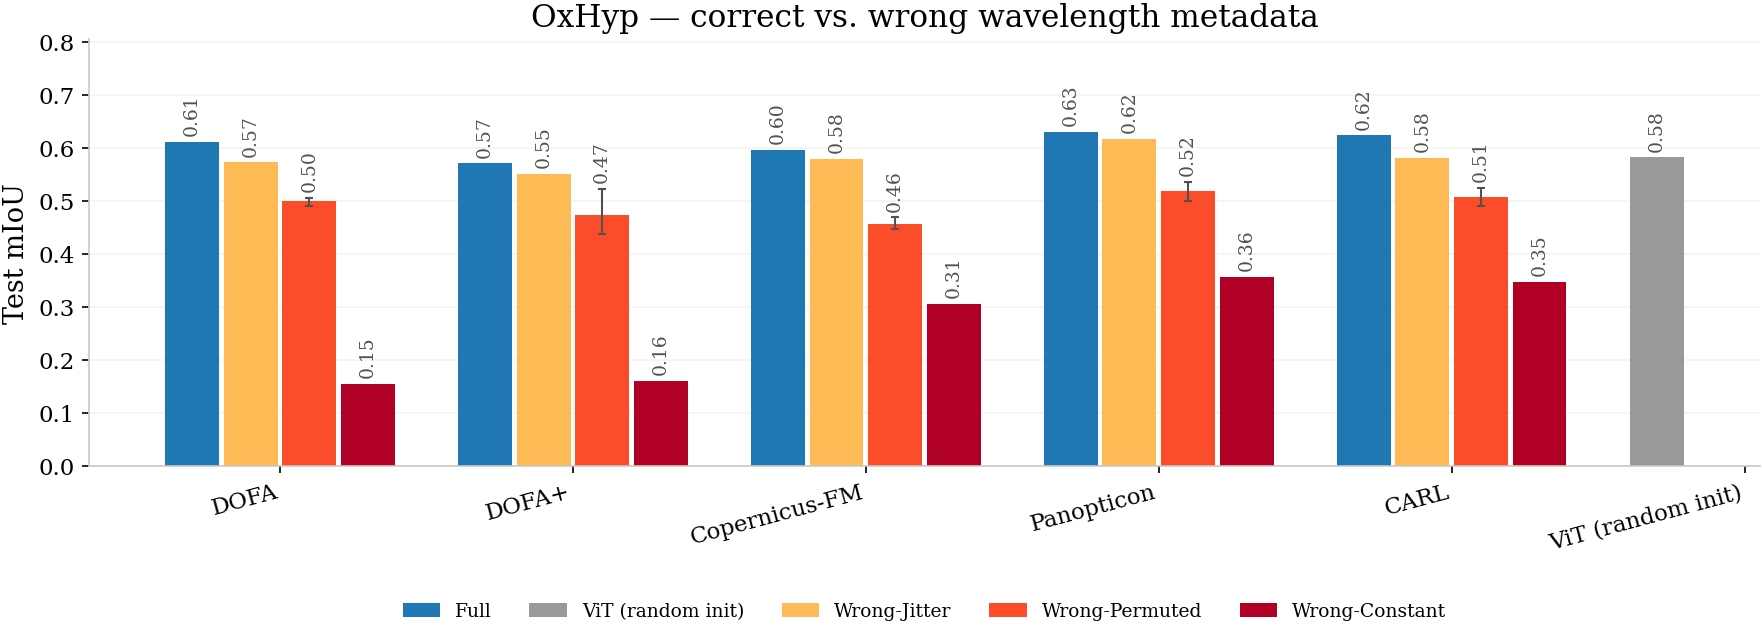

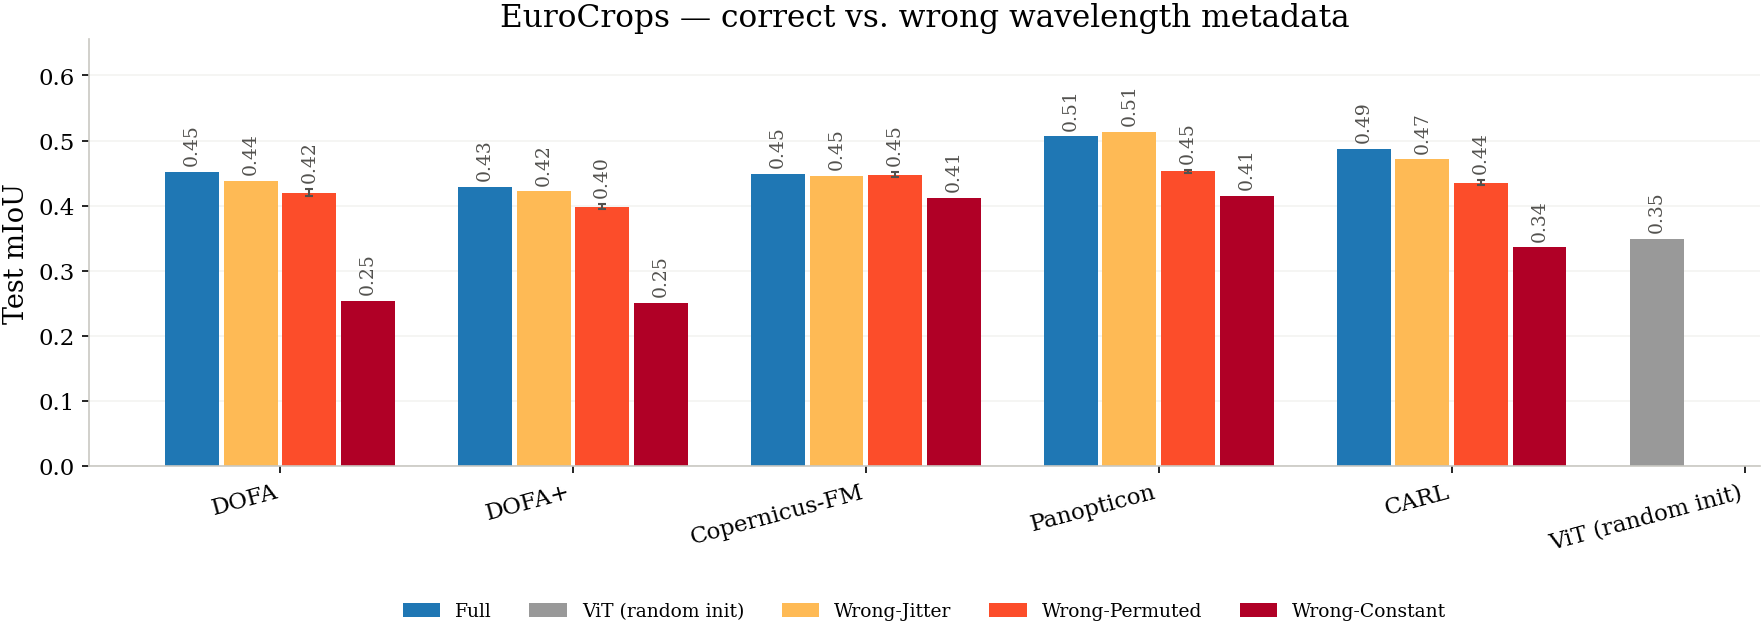

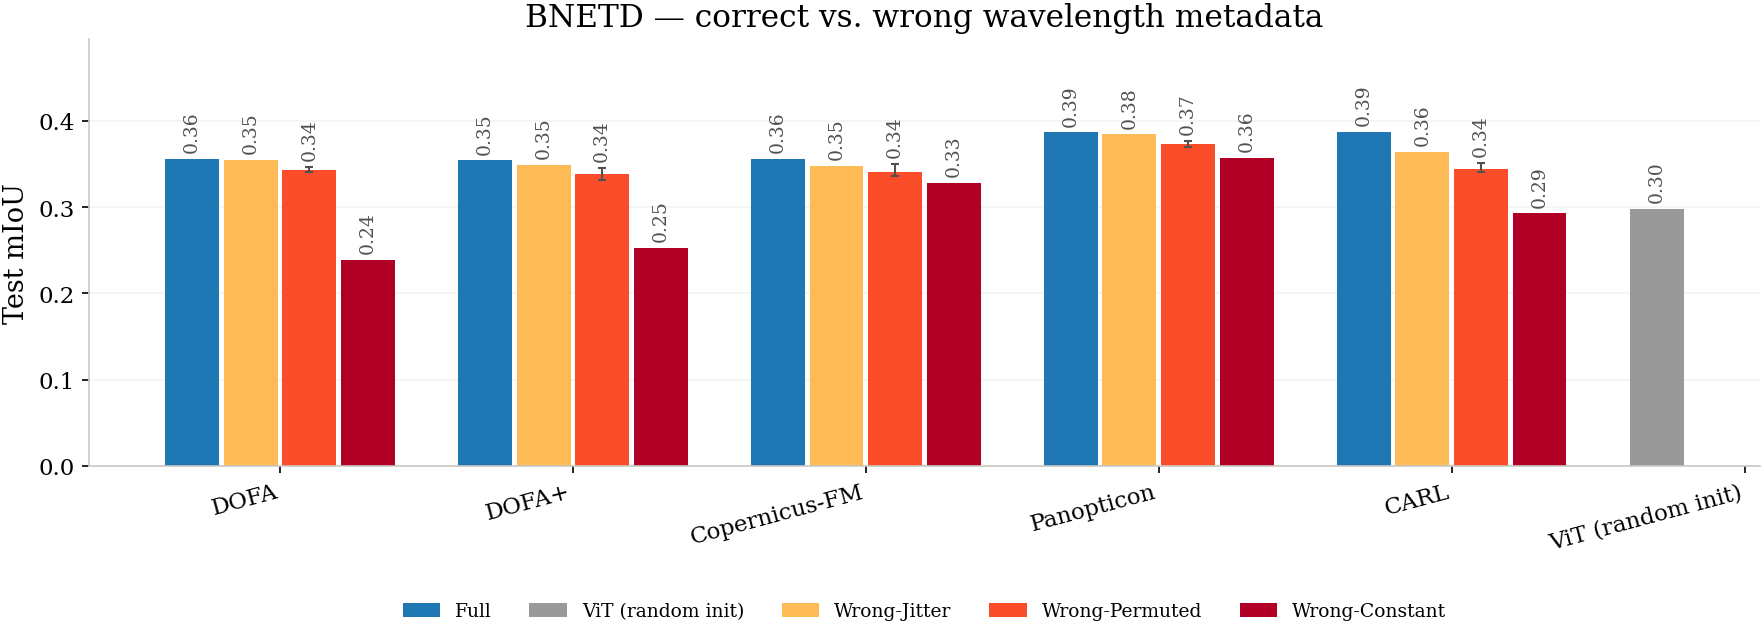

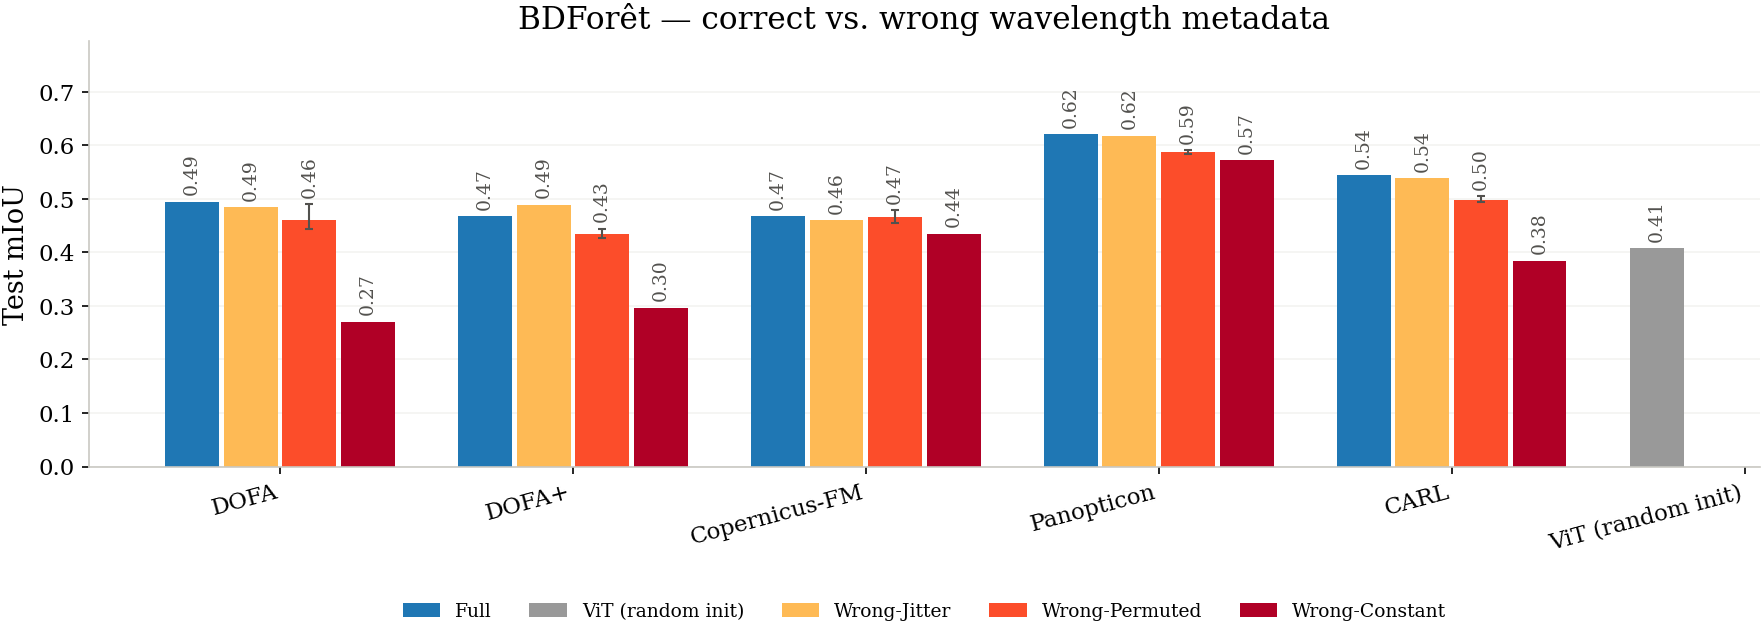

In [6]:
for task in TASKS:
    fig = plot_task_bars(all_long, task)
    fig.savefig(FIG_DIR / f"{task}_wrong_wavelength_bars.pdf", bbox_inches="tight")
    plt.show()

### Detailed tables

In [7]:
def pivot_condition(df: pd.DataFrame, condition: str, backbones: list[str], metric: str = "mIoU") -> pd.DataFrame:
    if condition == "wrong_permuted":
        subset = df[df["condition"] == "wrong_permuted"].groupby(["task", "backbone"], as_index=False)[metric].mean()
    else:
        subset = df[df["condition"] == condition]
    table = subset.pivot(index="backbone", columns="task", values=metric)
    row_order = [b for b in backbones if b in table.index]
    col_order = [t for t in TASKS if t in table.columns]
    table = table.reindex(index=row_order, columns=col_order)
    table.index = [BACKBONE_LABELS[b] for b in table.index]
    table.columns = [TASK_LABELS[t] for t in table.columns]
    return table


def style_table(df: pd.DataFrame, caption: str):
    return (
        df.style
        .format("{:.3f}", na_rep="\u2014")
        .highlight_max(axis=0, props="font-weight:bold;background-color:#e6f4ea;")
        .set_caption(caption)
    )


for condition in CONDITIONS:
    display(style_table(pivot_condition(all_long, condition, ALL_BACKBONES), f"{CONDITION_LABELS[condition]} -- test mIoU"))

,OxHyp,EuroCrops,BNETD,BDForêt
DOFA,0.612,0.452,0.356,0.495
DOFA+,0.571,0.429,0.354,0.468
Copernicus-FM,0.597,0.449,0.356,0.468
Panopticon,0.630,0.507,0.387,0.621
CARL,0.624,0.488,0.387,0.544
ViT (random init),0.582,0.349,0.298,0.408


,OxHyp,EuroCrops,BNETD,BDForêt
DOFA,0.573,0.438,0.355,0.485
DOFA+,0.550,0.422,0.349,0.489
Copernicus-FM,0.579,0.446,0.348,0.460
Panopticon,0.618,0.513,0.384,0.618
CARL,0.580,0.471,0.364,0.538


,OxHyp,EuroCrops,BNETD,BDForêt
DOFA,0.499,0.420,0.343,0.461
DOFA+,0.474,0.398,0.338,0.435
Copernicus-FM,0.456,0.448,0.341,0.466
Panopticon,0.519,0.453,0.373,0.587
CARL,0.507,0.435,0.345,0.499


,OxHyp,EuroCrops,BNETD,BDForêt
DOFA,0.154,0.253,0.239,0.271
DOFA+,0.160,0.251,0.252,0.297
Copernicus-FM,0.306,0.412,0.328,0.435
Panopticon,0.357,0.415,0.357,0.573
CARL,0.347,0.336,0.293,0.385


## What did the corruption actually assign?

Recomputes the same deterministic overrides `print_wrong_wavelength_overrides.py` used at submission
time (same seeds, same `random.Random(seed).sample(...)` permutation / `random.Random(seed).uniform(...)`
draws), so this is guaranteed to match what was actually run.

**Wrong-Constant**: every band on a sensor is told the same value — that sensor's **median true
wavelength**: **1286.5 nm for EMIT**, **998.6 nm for EnMAP** (a physically-plausible "middle of the
spectrum" pick, not an edge case like the min/max).

**Wrong-Permuted**: the slope chart below has two columns — **True** wavelength on the left, **Wrong**
(assigned) wavelength on the right — with a line connecting each band's true value to whatever value it
got told instead. One panel per seed. Lines are colored by the band's true wavelength (a light->dark
blue ramp, short->long) so you can also see whether short-wavelength bands systematically land anywhere
in particular on the right (they shouldn't, for a genuine uniform permutation) rather than just seeing
an undifferentiated tangle. The dotted horizontal line marks the Wrong-Constant value for reference.

**Shuffled** reuses seed 0's exact permutation from the chart above — same "Wrong" wavelength values,
same left→right mapping — but (unlike Wrong-Permuted) also reorders the pixel data by that permutation,
so at every position the data and its wavelength label agree; only the band *order* changes.

**Wrong-Jitter** is a different, much smaller perturbation: each band keeps its own true wavelength as
an anchor, moved by an independently-drawn offset (magnitude uniform in [20, 50] nm, random sign). The
plot below shows that per-band signed offset directly (not a True→Wrong mapping, since here every band
keeps its own identity) — points should scatter uniformly across the shaded [-50, -20] / [20, 50] nm
bands with no offset ever landing inside the unshaded gap.

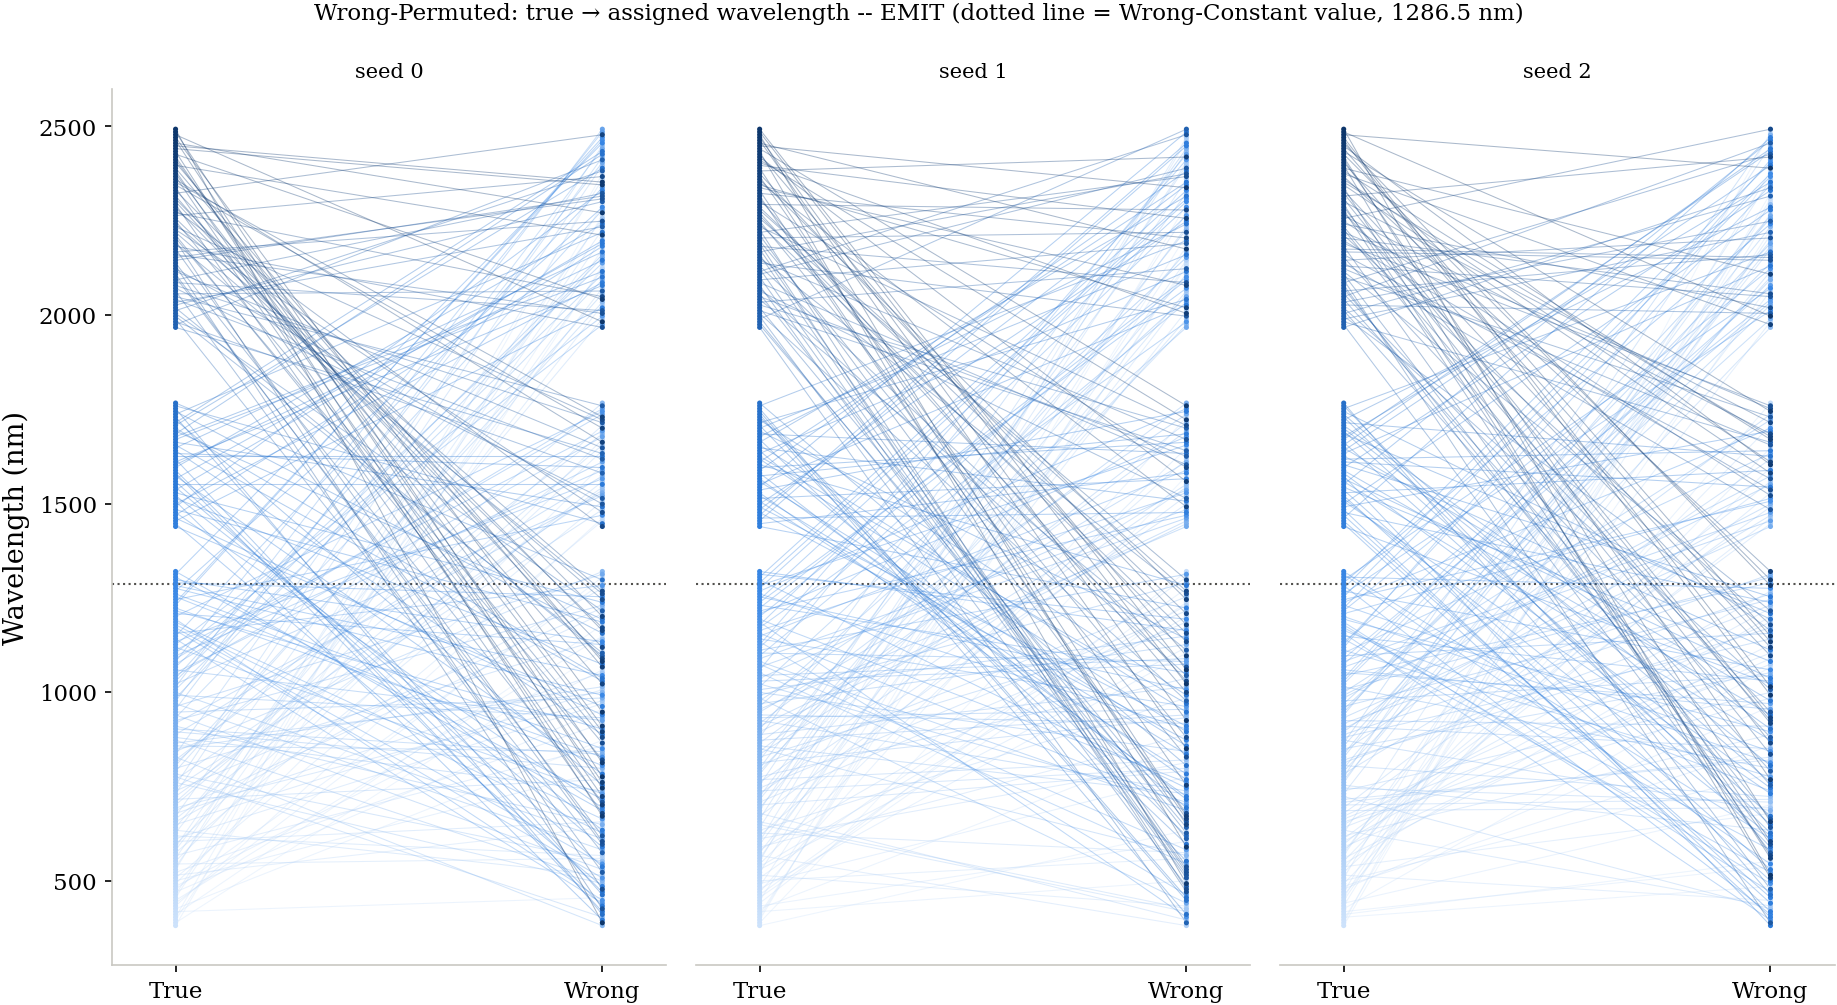

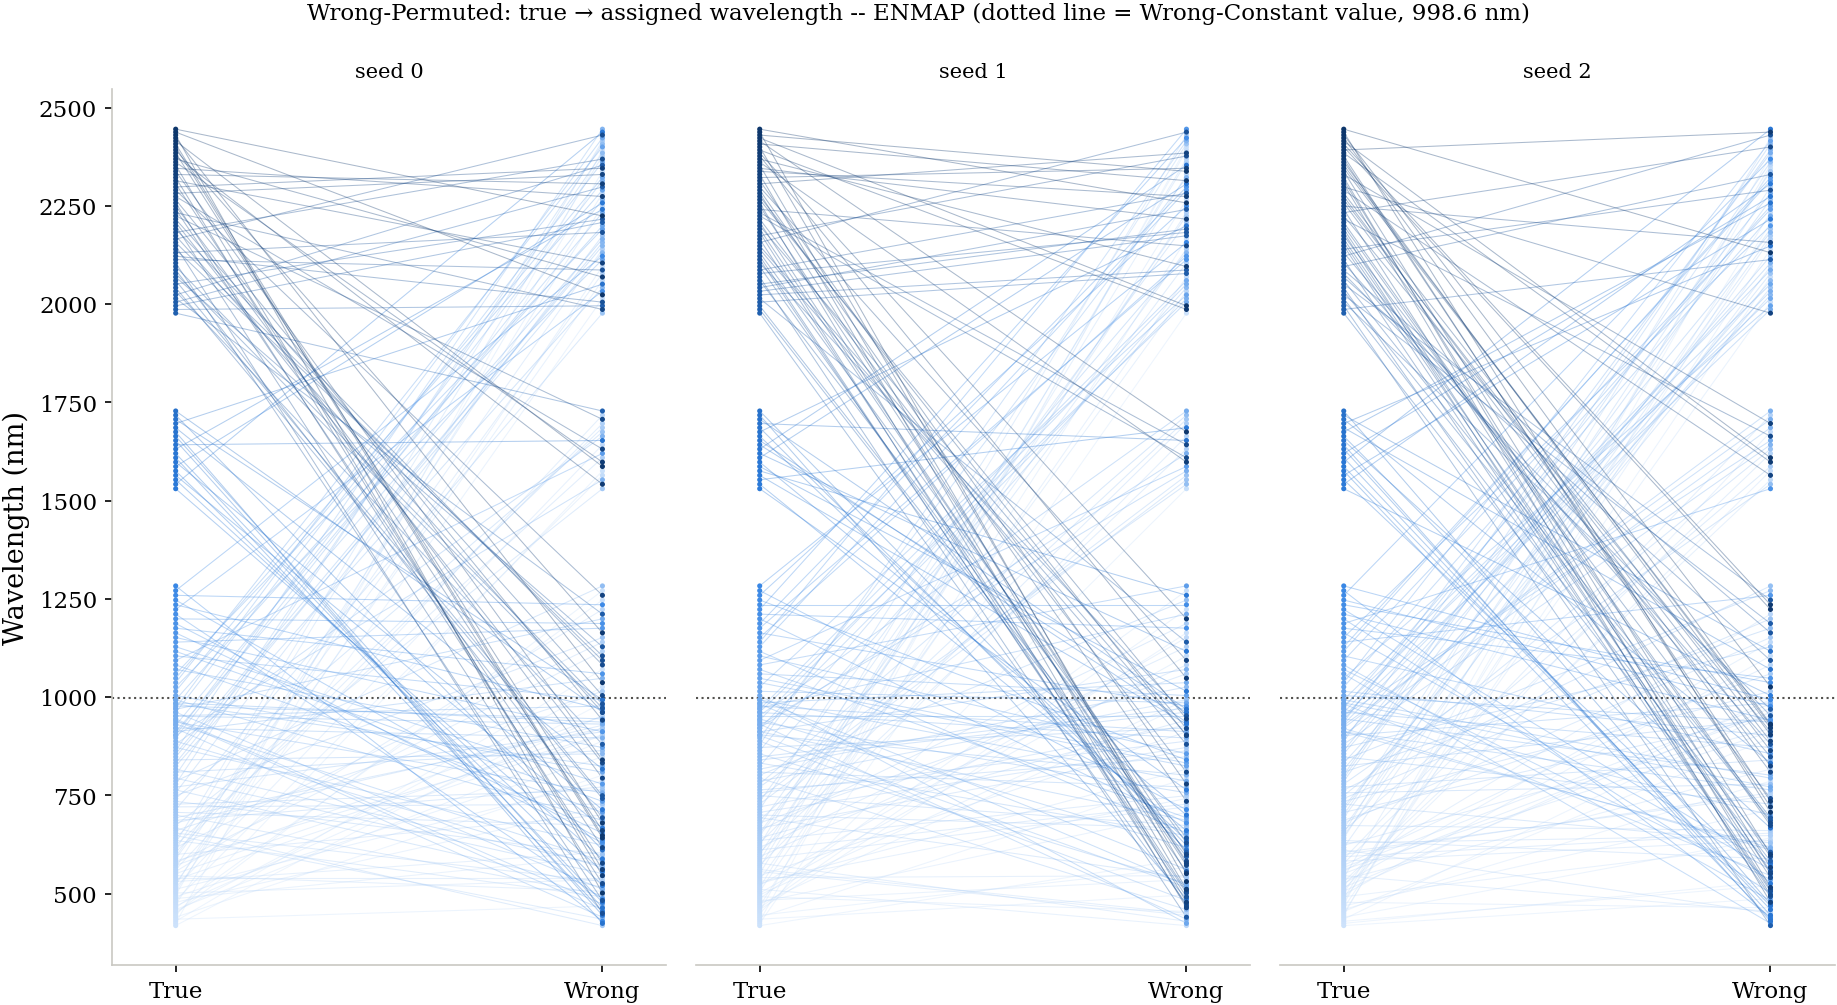

In [8]:
from matplotlib.colors import LinearSegmentedColormap

# Sequential blue ramp (light -> dark), same palette family used elsewhere in
# this notebook's "full"/CONDITION_COLORS blue -- steps 100->700 from the
# dataviz skill's reference blue ramp.
_BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#256abf", "#184f95", "#0d366b"]
)


def load_sensor_wavelengths(sensor: str) -> list[float]:
    with SENSOR_YAML_PATHS[sensor].open() as f:
        cfg = yaml.safe_load(f)
    metadata_path = REPO_ROOT / cfg["spectral"]["processed_band_metadata_path"]
    with metadata_path.open(newline="") as f:
        rows = list(csv.DictReader(f))
    return [float(row["wavelength_nm"]) for row in rows]


def plot_permutation_slopes(sensor: str):
    wavelengths = load_sensor_wavelengths(sensor)
    num_bands = len(wavelengths)
    constant_value = statistics.median(wavelengths)
    lo, hi = min(wavelengths), max(wavelengths)
    norm = [(w - lo) / (hi - lo) for w in wavelengths]

    fig, axes = plt.subplots(1, len(SEEDS), figsize=(4.2 * len(SEEDS), 7), sharey=True)
    for ax, seed in zip(axes, SEEDS):
        rng = random.Random(seed)
        perm = rng.sample(range(num_bands), num_bands)
        wrong_wavelengths = [wavelengths[i] for i in perm]

        for true_w, wrong_w, t in zip(wavelengths, wrong_wavelengths, norm):
            ax.plot([0, 1], [true_w, wrong_w], color=_BLUE_RAMP(t), linewidth=0.5, alpha=0.35, zorder=2)
        ax.scatter([0] * num_bands, wavelengths, c=norm, cmap=_BLUE_RAMP, s=6, zorder=3, edgecolors="none")
        ax.scatter([1] * num_bands, wrong_wavelengths, c=norm, cmap=_BLUE_RAMP, s=6, zorder=3, edgecolors="none")

        ax.axhline(constant_value, color=TEXT_MUTED, linewidth=1, linestyle=":", zorder=1)
        ax.set_xlim(-0.15, 1.15)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["True", "Wrong"])
        ax.set_title(f"seed {seed}", fontsize=10)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(seed == SEEDS[0])
        if seed != SEEDS[0]:
            ax.tick_params(left=False)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Wavelength (nm)")
    fig.suptitle(
        f"Wrong-Permuted: true → assigned wavelength -- {sensor.upper()} "
        f"(dotted line = Wrong-Constant value, {constant_value:.1f} nm)",
        fontsize=11,
    )
    fig.tight_layout()
    plt.show()


for sensor in ["emit", "enmap"]:
    plot_permutation_slopes(sensor)

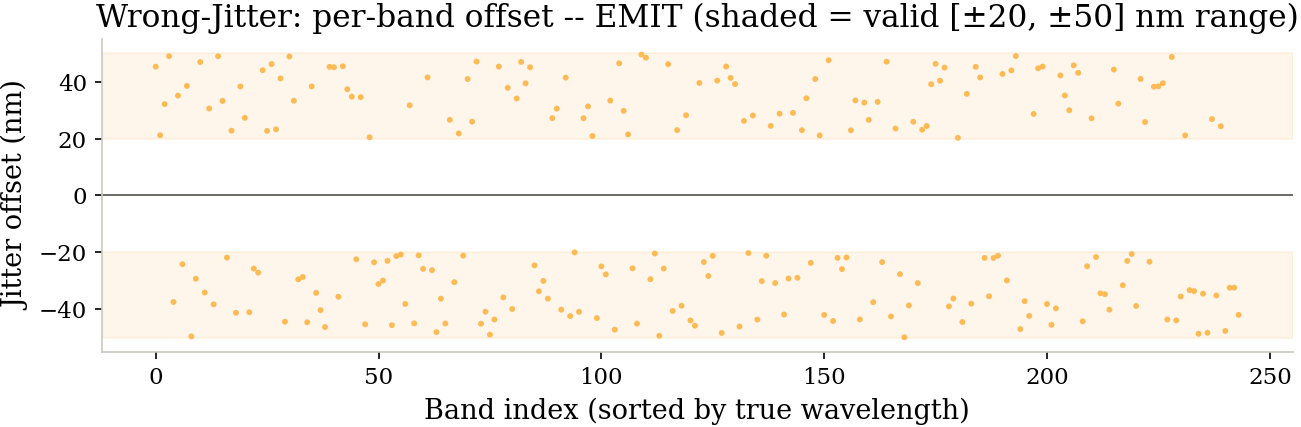

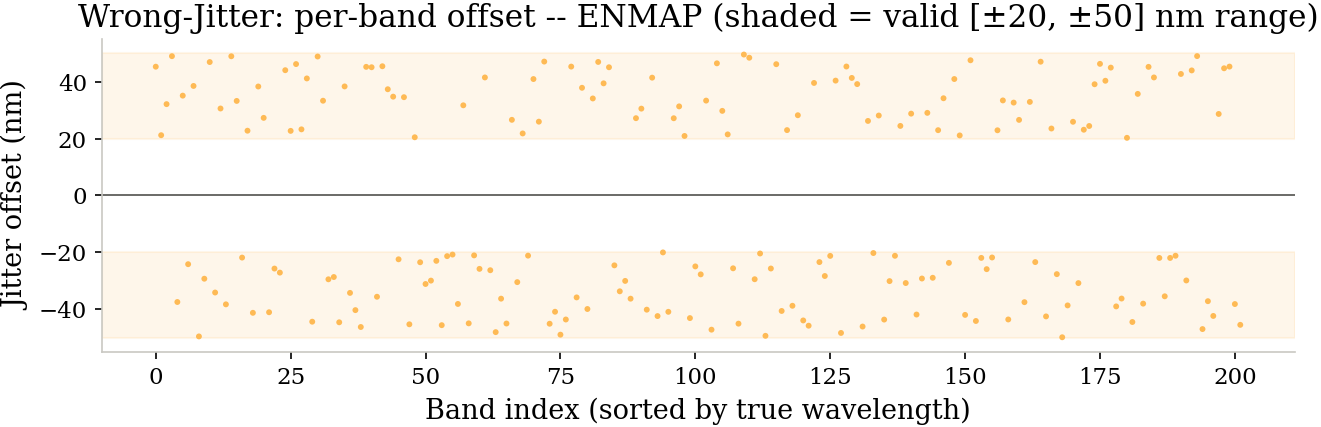

In [9]:
JITTER_MIN_NM = 20.0
JITTER_MAX_NM = 50.0
JITTER_SEED = 0


def plot_jitter_offsets(sensor: str):
    wavelengths = load_sensor_wavelengths(sensor)
    rng = random.Random(JITTER_SEED)
    offsets = []
    for w in wavelengths:
        magnitude = rng.uniform(JITTER_MIN_NM, JITTER_MAX_NM)
        sign = rng.choice([-1.0, 1.0])
        offsets.append(sign * magnitude)

    order = np.argsort(wavelengths)
    sorted_offsets = [offsets[i] for i in order]

    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.axhspan(JITTER_MIN_NM, JITTER_MAX_NM, color=CONDITION_COLORS["wrong_jitter"], alpha=0.12, zorder=1)
    ax.axhspan(-JITTER_MAX_NM, -JITTER_MIN_NM, color=CONDITION_COLORS["wrong_jitter"], alpha=0.12, zorder=1)
    ax.axhline(0, color=TEXT_MUTED, linewidth=0.8, zorder=2)
    ax.scatter(
        range(len(sorted_offsets)), sorted_offsets, s=8,
        color=CONDITION_COLORS["wrong_jitter"], edgecolors="none", zorder=3,
    )
    ax.set_xlabel("Band index (sorted by true wavelength)")
    ax.set_ylabel("Jitter offset (nm)")
    ax.set_title(f"Wrong-Jitter: per-band offset -- {sensor.upper()} (shaded = valid [±20, ±50] nm range)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()


for sensor in ["emit", "enmap"]:
    plot_jitter_offsets(sensor)

## Cost of wrong wavelength metadata

For each (task, encoder): how much mIoU is lost going from Full to each wrong-wavelength condition.
Only computed for the 5 wavelength-conditioned encoders (ViT-B/UniverSat-B excluded — ViT-B has no
wrong-wavelength conditions at all; UniverSat-B's Shuffled run may still be incomplete).

In [10]:
def wrong_wavelength_cost_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for task in TASKS:
        for backbone in BACKBONES:
            sub = df[(df.task == task) & (df.backbone == backbone)]
            full = sub[sub.condition == "full"]["mIoU"]
            permuted = sub[sub.condition == "wrong_permuted"]["mIoU"].dropna()
            constant = sub[sub.condition == "wrong_constant"]["mIoU"]
            jitter = sub[sub.condition == "wrong_jitter"]["mIoU"]
            shuffled = sub[sub.condition == "shuffled"]["mIoU"]
            full_v = full.iloc[0] if len(full) else None
            rows.append({
                "task": TASK_LABELS[task],
                "backbone": BACKBONE_LABELS[backbone],
                "full_mIoU": full_v,
                "wrong_permuted_mean_mIoU": permuted.mean() if len(permuted) else None,
                "wrong_permuted_drop": (full_v - permuted.mean()) if full_v is not None and len(permuted) else None,
                "wrong_constant_mIoU": constant.iloc[0] if len(constant) else None,
                "wrong_constant_drop": (full_v - constant.iloc[0]) if full_v is not None and len(constant) else None,
                "wrong_jitter_mIoU": jitter.iloc[0] if len(jitter) else None,
                "wrong_jitter_drop": (full_v - jitter.iloc[0]) if full_v is not None and len(jitter) else None,
                "shuffled_mIoU": shuffled.iloc[0] if len(shuffled) else None,
                "shuffled_drop": (full_v - shuffled.iloc[0]) if full_v is not None and len(shuffled) else None,
            })
    return pd.DataFrame(rows)


cost_table = wrong_wavelength_cost_table(results_long)
(
    cost_table.style
    .format("{:.3f}", subset=[c for c in cost_table.columns if c not in ("task", "backbone")], na_rep="—")
    .background_gradient(
        cmap="RdYlGn_r",
        subset=["wrong_permuted_drop", "wrong_constant_drop", "wrong_jitter_drop", "shuffled_drop"],
        vmin=-0.05, vmax=0.3,
    )
    .set_caption("mIoU lost relative to Full when wavelength metadata is wrong (positive = wrong-wavelength hurts)")
)

,task,backbone,full_mIoU,wrong_permuted_mean_mIoU,wrong_permuted_drop,wrong_constant_mIoU,wrong_constant_drop,wrong_jitter_mIoU,wrong_jitter_drop,shuffled_mIoU,shuffled_drop
0,OxHyp,DOFA,0.612,0.499,0.112,0.154,0.457,0.573,0.039,0.618,-0.007
1,OxHyp,DOFA+,0.571,0.474,0.096,0.160,0.410,0.550,0.020,0.571,-0.001
2,OxHyp,Copernicus-FM,0.597,0.456,0.141,0.306,0.291,0.579,0.018,0.591,0.006
3,OxHyp,Panopticon,0.630,0.519,0.111,0.357,0.273,0.618,0.012,0.643,-0.013
4,OxHyp,CARL,0.624,0.507,0.116,0.347,0.276,0.580,0.043,0.629,-0.005
5,EuroCrops,DOFA,0.452,0.420,0.032,0.253,0.199,0.438,0.014,0.451,0.001
6,EuroCrops,DOFA+,0.429,0.398,0.031,0.251,0.178,0.422,0.007,0.434,-0.005
7,EuroCrops,Copernicus-FM,0.449,0.448,0.002,0.412,0.037,0.446,0.003,0.448,0.001
8,EuroCrops,Panopticon,0.507,0.453,0.054,0.415,0.092,0.513,-0.007,0.510,-0.003
9,EuroCrops,CARL,0.488,0.435,0.052,0.336,0.151,0.471,0.017,0.485,0.002


### Does the drop hold across all 3 permuted seeds?

Same caution as the random-band-ablation notebook: 3 seeds is enough to see a large, consistent effect
but not enough to rule out one seed driving the result. Checks whether each individual permutation seed
scores below Full, per (task, encoder).

In [11]:
def seed_consistency_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for task in TASKS:
        for backbone in BACKBONES:
            sub = df[(df.task == task) & (df.backbone == backbone)]
            full = sub[sub.condition == "full"]["mIoU"]
            if not len(full):
                continue
            full_v = full.iloc[0]
            row = {"task": TASK_LABELS[task], "backbone": BACKBONE_LABELS[backbone], "full_mIoU": full_v}
            below_count = 0
            total = 0
            for seed in SEEDS:
                v = sub[(sub.condition == "wrong_permuted") & (sub.seed == seed)]["mIoU"]
                if len(v):
                    total += 1
                    row[f"seed{seed}_mIoU"] = v.iloc[0]
                    if v.iloc[0] < full_v:
                        below_count += 1
                else:
                    row[f"seed{seed}_mIoU"] = None
            row["seeds_below_full"] = f"{below_count}/{total}" if total else "\u2014"
            rows.append(row)
    return pd.DataFrame(rows)


consistency_table = seed_consistency_table(results_long)
(
    consistency_table.style
    .format("{:.3f}", subset=[c for c in consistency_table.columns if "mIoU" in c], na_rep="\u2014")
    .set_caption("Per-seed wrong-permuted score vs. Full -- seeds_below_full counts how many of the 3 draws scored worse than Full")
)

,task,backbone,full_mIoU,seed0_mIoU,seed1_mIoU,seed2_mIoU,seeds_below_full
0,OxHyp,DOFA,0.612,0.505,0.490,0.502,3/3
1,OxHyp,DOFA+,0.571,0.462,0.438,0.523,3/3
2,OxHyp,Copernicus-FM,0.597,0.469,0.447,0.451,3/3
3,OxHyp,Panopticon,0.630,0.536,0.521,0.500,3/3
4,OxHyp,CARL,0.624,0.491,0.524,0.507,3/3
5,EuroCrops,DOFA,0.452,0.419,0.415,0.426,3/3
6,EuroCrops,DOFA+,0.429,0.396,0.395,0.403,3/3
7,EuroCrops,Copernicus-FM,0.449,0.446,0.452,0.445,2/3
8,EuroCrops,Panopticon,0.507,0.455,0.450,0.454,3/3
9,EuroCrops,CARL,0.488,0.433,0.440,0.432,3/3


## Takeaways

**Damage scales cleanly with how much wavelength information is actually destroyed.** Averaged across
the 5 encoders × 3 original tasks, the ordering is stark: **Shuffled ≈ −0.001** (no measurable cost —
see below), **Wrong-Jitter = 0.014**, **Wrong-Permuted = 0.056**, **Wrong-Constant = 0.182** mIoU. That
is exactly the order in which each condition destroys information: Shuffled destroys *none* (every band
still gets its own true wavelength, just reordered), Wrong-Jitter adds a small random offset but keeps
each band's value close to correct, Wrong-Permuted keeps the true value population but scrambles which
band gets which, and Wrong-Constant erases all cross-channel differentiation entirely. This ordering
holds for every individual (task, encoder) combination — it is not an artifact of averaging.

**Shuffled is the cleanest possible confirmation that these encoders don't need canonical band order.**
With correct (data, wavelength) pairing at every position, reordering the bands costs essentially
nothing — the mean drop is slightly *negative* (−0.001), and 7 of 15 (task, encoder) combinations
actually score marginally *higher* than Full-band-order, well within noise. Wavelength conditioning is
doing exactly the job it should: telling the encoder what each channel means regardless of what
position it arrives in, so there is no hidden reliance on spectrally-adjacent neighbors or a fixed
channel index.

**Wrong-Jitter shows real but modest sensitivity to calibration-drift-sized noise.** A random ±20–50 nm
per-band offset costs 0.014 mIoU on average — about a quarter of Wrong-Permuted's damage — and every
task/encoder combination except one shows a real, if small, drop. Encoders tolerate being
*approximately* right about wavelength far better than being told a plausible but *specifically wrong*
band identity.

**Wrong-Constant is the clean load-bearing-conditioning test, and it's decisive.** Removing all
cross-channel differentiation from the wavelength signal costs as much as 0.457 mIoU (DOFA-B, OxHyp) —
often more than half the encoder's total score. Wavelength conditioning is not decoration these
encoders could equally have learned as a fixed positional embedding: give them a signal that can no
longer tell channels apart and performance collapses accordingly.

**Wrong-Permuted's damage is strongly task-dependent — and BDForêt joins EuroCrops/BNETD as a
"forgiving" task, not OxHyp's camp.** OxHyp (mineral segmentation) shows by far the largest permuted-
seed drop (0.10–0.14 across all 5 encoders) — specific minerals favor specific narrow bands, so telling
the encoder the wrong specific band is genuinely misleading there. EuroCrops/BNETD/BDForêt are all far
more forgiving of a scrambled-but-still-real value set (BDForêt: 0.002–0.045 drop) — broad
crop/forest/vegetation classification apparently leans on spectral *shape* far more than on any single
band's exact identity. The same split shows up in Wrong-Constant too: BDForêt's drop ranges from a
near-nothing 0.032 (Copernicus-FM-B — its bandwidth input keeps supplying differentiation even when
center-wavelength is constant, same as on the other 3 tasks) up to a real 0.224 (DOFA-B), mirroring the
per-encoder ordering already seen on EuroCrops/BNETD rather than introducing a new pattern.

**Reinit-Hypernetwork reveals that the *pretrained, learned* weight-generation mapping matters — and by
how much depends entirely on the task, not the corruption's severity in the abstract.** With wavelength
metadata left completely correct, just replacing the encoder's own weight-generator with a fresh
standard init drops performance to **83–90% of Full on EuroCrops/BNETD** (DOFA-B: 0.452→0.374;
DOFAv2-B: 0.354→0.319) — modest, in the same range as Wrong-Permuted on those tasks. But on OxHyp,
Copernicus-FM-B's reinitialized hypernetwork retains only **52% of Full** (0.597→0.312) — a drop nearly
as large as full Wrong-Constant collapse (0.306) on the same (task, encoder). In other words: an
*untrained* hypernetwork that's still told the truth about every band behaves like a *trained*
hypernetwork told a wrong-but-plausible band identity (Wrong-Permuted) on the tasks that don't care much
about precise band semantics, but behaves like *all differentiation being destroyed* (Wrong-Constant) on
the one task that does. This is the sharpest available evidence that OxHyp specifically depends on
*learned*, pretrained wavelength→weight semantics — not just *some* differentiated per-band signal, the
way EuroCrops/BNETD apparently do. Now complete across all 3 applicable encoders × 4 tasks (12/12).

**Actively wrong wavelength info can be worse than no wavelength info at all.** ViT-B (random init, no
wavelength conditioning whatsoever) scores 0.58 mIoU full-band on OxHyp — comfortably *above* every
wavelength-conditioned encoder's Wrong-Constant score (0.15–0.36) on the same task, and close to or
above several of them on EuroCrops/BNETD/BDForêt too. A model that never had a wavelength concept to
begin with holds up better than one whose wavelength concept has been actively broken — the
conditioning mechanism isn't just unused when given bad input, it seems to actively interfere.

**Caveat**: 152/152 wavelength-conditioned-encoder combinations complete, including Reinit-Hypernetwork
at 12/12. ViT-B is 4/4 and UniverSat-B is 21/21 (scoped to its original 3 tasks only — BDForêt was
dropped for UniverSat-B specifically after repeated requeue-ceiling timeouts even at 36h, not going in
the thesis). Reinit-Hypernetwork is restricted to DOFA-B/DOFAv2-B/Copernicus-FM-B — Panopticon-B/CARL
use different conditioning mechanisms with no equivalent submodule to reinit. As with the
random-band-ablation notebook, 3 permutation seeds (and 1 seed each for Wrong-Jitter/Shuffled/
Reinit-Hypernetwork) are enough to see a large, consistent effect but not enough on their own to rule
out seed-to-seed variance at the smaller-effect (task, encoder) combinations — see the per-seed table
above for Wrong-Permuted specifically.